# 实验 14：让去噪生成模型真正去噪

本 notebook 对应论文 **Back to Basics: Let Denoising Generative Models Denoise** 的核心观点：虽然 $x$、噪声 $\epsilon$ 与速度 $v$ 可以解析互换，但有限容量神经网络直接学习三者时，难度可能不同。

实验统一采用：

$$
x_t=(1-t)x_0+tx_1,\qquad v=x_1-x_0,
$$

其中 $x_0$ 是初始噪声，$x_1$ 是真实数据。整个 notebook 实际运行以下 63 个训练配置和 1 个无需训练的数学验证：

| 实验 | 内容 | 训练组数 |
|---|---|---:|
| D | 投影与高维噪声能量 | 0 |
| A | Prediction × Loss × Dimension | 27 |
| B | 网络容量瓶颈 | 12 |
| C | 解析残差参数化 | 3 |
| E | 噪声协方差消融 | 9 |
| G | 时间区间消融 | 9 |
| F | 简化 JiT 图像生成 | 3 |

默认使用适合单张消费级 GPU 的教学配置，使所有实验可以在一次执行中完成。把 `QUICK_RUN=False` 后可增加训练步数，但完整研究结论仍应使用多个随机种子报告均值和标准差。

In [1]:
import copy
import gc
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFilter

SEED = 42
QUICK_RUN = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = Path("meanflow_outputs").parent / "let_dgm_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 教学运行仍覆盖全部 63 个配置，只缩短每个配置的训练步数。
STEPS = {
    "A": 1200 if QUICK_RUN else 5000,
    "B": 250 if QUICK_RUN else 4000,
    "C": 350 if QUICK_RUN else 5000,
    "E": 300 if QUICK_RUN else 5000,
    "G": 250 if QUICK_RUN else 4000,
    "F": 600 if QUICK_RUN else 10000,
}
BATCH_SIZE = 1024
SAMPLE_SIZE = 256
ODE_STEPS = 30 if QUICK_RUN else 100

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
print(f"device={DEVICE}, quick_run={QUICK_RUN}, output={OUTPUT_DIR.resolve()}")
if DEVICE.type == "cuda":
    print(torch.cuda.get_device_name(0))

device=cuda, quick_run=True, output=/home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/let_dgm_outputs
NVIDIA GeForce GTX 1050 Ti


## 1. 公共数据、投影和指标

真实数据是二维无条件四峰高斯混合分布，经列正交矩阵 $P\in\mathbb R^{D\times2}$ 嵌入 $D$ 维环境空间：

$$
z_1\in\mathbb R^2,\qquad x_1=Pz_1,\qquad P^\top P=I_2.
$$

代码使用行向量批次，因此实际计算写成 `x1 = z1 @ P.T`。投影矩阵无需显式构造：$xP P^\top$ 可写成 `(x @ P) @ P.T`，这样在 $D$ 较大时更节省内存。

In [2]:
INTRINSIC_DIM = 2
NUM_MODES = 4
TARGET_STD = 0.25
# 与参考 train.py 相同的四个峰，但这里不向模型注入峰类别条件。
MODE_CENTERS = torch.tensor(((2., 0.), (-2., 0.), (0., 2.), (0., -2.)), dtype=torch.float32)

def make_basis(ambient_dim, seed=SEED):
    """生成 D×2 的列正交嵌入矩阵。"""
    generator = torch.Generator(device="cpu").manual_seed(seed + ambient_dim)
    matrix = torch.randn(ambient_dim, INTRINSIC_DIM, generator=generator)
    q, _ = torch.linalg.qr(matrix, mode="reduced")
    return q.to(DEVICE)

def sample_latent(n, device=DEVICE):
    """无条件二维四峰目标分布；峰标签不会输入模型。"""
    ids = torch.randint(NUM_MODES, (n,), device=device)
    centers = MODE_CENTERS.to(device)[ids]
    return centers + TARGET_STD * torch.randn(n, 2, device=device)

def sample_pair(n, basis, sigma_parallel=1.0, sigma_perp=1.0):
    """采样真实数据 x1 和可控子空间内外方差的初始噪声 x0。"""
    z1 = sample_latent(n, basis.device)
    x1 = z1 @ basis.T
    eps = torch.randn_like(x1)
    eps_parallel = (eps @ basis) @ basis.T
    eps_perp = eps - eps_parallel
    x0 = sigma_parallel * eps_parallel + sigma_perp * eps_perp
    return x0, x1, z1

def split_energy(x, basis):
    parallel = (x @ basis) @ basis.T
    perpendicular = x - parallel
    return parallel.square().sum(-1), perpendicular.square().sum(-1)

def rbf_mmd2(x, y):
    """二维投影上的无偏 RBF-MMD²；带宽由真实样本中位距离确定。"""
    x, y = x.float(), y.float()
    dxx = torch.cdist(x, x).square()
    positive = dxx[dxx > 0]
    bandwidth = positive.median().clamp_min(1e-6)
    kxx = torch.exp(-dxx / bandwidth)
    kyy = torch.exp(-torch.cdist(y, y).square() / bandwidth)
    kxy = torch.exp(-torch.cdist(x, y).square() / bandwidth)
    n, m = len(x), len(y)
    xx = (kxx.sum() - kxx.diag().sum()) / (n * (n - 1))
    yy = (kyy.sum() - kyy.diag().sum()) / (m * (m - 1))
    return float((xx + yy - 2 * kxy.mean()).detach().cpu())

def mode_coverage(z, threshold=0.05):
    ids = torch.cdist(z, MODE_CENTERS.to(z.device)).argmin(1)
    freq = torch.bincount(ids, minlength=NUM_MODES).float() / len(z)
    return int((freq >= threshold).sum()), freq.detach().cpu().numpy()

## 2. 实验 D：投影与高维噪声能量

这部分不训练模型，直接验证：

$$
\mathbb E\|\Pi x_0\|^2=d,\qquad
\mathbb E\|(I-\Pi)x_0\|^2=D-d,
$$

以及由于 $(I-\Pi)x_1=0$：

$$
\mathbb E\|(I-\Pi)v\|^2=D-d.
$$

还会在 $D=32$ 下随机生成十个不同朝向的子空间，验证各向同性高斯的结果与朝向无关。

In [3]:
energy_rows = []
with torch.no_grad():
    for ambient_dim in [2, 32, 256]:
        basis = make_basis(ambient_dim, seed=100)
        x0, x1, _ = sample_pair(20000, basis)
        velocity = x1 - x0
        x0_par, x0_perp = split_energy(x0, basis)
        _, x1_perp = split_energy(x1, basis)
        _, v_perp = split_energy(velocity, basis)
        energy_rows.append({
            "D": ambient_dim,
            "theory_parallel": 2,
            "empirical_parallel": float(x0_par.mean()),
            "theory_perp": ambient_dim - 2,
            "noise_perp": float(x0_perp.mean()),
            "data_perp": float(x1_perp.mean()),
            "velocity_perp": float(v_perp.mean()),
        })

    orientation_values = []
    for orientation in range(10):
        basis = make_basis(32, seed=1000 + orientation)
        x0, _, _ = sample_pair(10000, basis)
        orientation_values.append(float(split_energy(x0, basis)[1].mean()))

print("投影能量验证：")
for row in energy_rows:
    print(row)
print(f"D=32 十种朝向: mean={np.mean(orientation_values):.4f}, std={np.std(orientation_values):.4f}, theory=30")

投影能量验证：
{'D': 2, 'theory_parallel': 2, 'empirical_parallel': 1.9945597648620605, 'theory_perp': 0, 'noise_perp': 2.948516268381357e-14, 'data_perp': 6.047073920160267e-14, 'velocity_perp': 9.035117489245015e-14}
{'D': 32, 'theory_parallel': 2, 'empirical_parallel': 1.9982097148895264, 'theory_perp': 30, 'noise_perp': 30.02933120727539, 'data_perp': 4.71038850557038e-14, 'velocity_perp': 30.02933120727539}
{'D': 256, 'theory_parallel': 2, 'empirical_parallel': 2.024076223373413, 'theory_perp': 254, 'noise_perp': 254.0118408203125, 'data_perp': 2.496094422734657e-13, 'velocity_perp': 254.0118408203125}
D=32 十种朝向: mean=30.0242, std=0.0897, theory=30


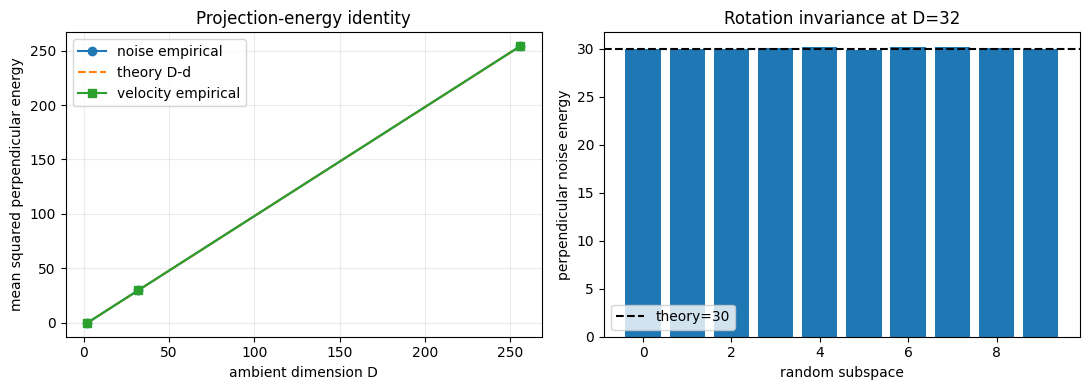

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
dims = [row["D"] for row in energy_rows]
axes[0].plot(dims, [row["noise_perp"] for row in energy_rows], "o-", label="noise empirical")
axes[0].plot(dims, [d - 2 for d in dims], "--", label="theory D-d")
axes[0].plot(dims, [row["velocity_perp"] for row in energy_rows], "s-", label="velocity empirical")
axes[0].set(xlabel="ambient dimension D", ylabel="mean squared perpendicular energy", title="Projection-energy identity")
axes[0].legend()
axes[0].grid(alpha=0.25)
axes[1].bar(np.arange(10), orientation_values)
axes[1].axhline(30, color="black", ls="--", label="theory=30")
axes[1].set(xlabel="random subspace", ylabel="perpendicular noise energy", title="Rotation invariance at D=32")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_projection_energy.png", dpi=160)
plt.show()

## 3. Prediction Space、Loss Space 与统一训练框架

网络原始输出按 `pred_type` 解释为 $\hat x_1$、$\hat x_0$ 或 $\hat v$，再解析转换到三个空间：

$$
\begin{aligned}
\hat v_x&=\frac{\hat x_1-x_t}{1-t},\\
\hat v_\epsilon&=\frac{x_t-\hat x_0}{t},\\
\hat x_1&=x_t+(1-t)\hat v,\qquad
\hat x_0=x_t-t\hat v.
\end{aligned}
$$

这样任何 Prediction Space 都可以配合 $x$、$\epsilon$ 或 $v$ Loss。训练避开端点以控制除法的数值条件。评价统一转换到速度空间，并把误差拆成数据子空间内和正交补两部分。

### 端点与分母截断

最初版本只在 $t\in[0.05,0.95]$ 训练，却在采样时评估到接近 $t=1$ 的位置。对 x-prediction 而言，$1/(1-t)$ 会放大这种终点外推误差。本版主实验把时间覆盖扩展为 $[0.001,0.999]$。

九种交叉组合中的解析 Loss 换算仍可能产生 $1/t^2$ 或 $1/(1-t)^2$ 权重。训练时将分母下界截断为 0.05，防止极少数端点样本支配整个 batch；推理时使用 $10^{-3}$ 的数值下界，不改变正常积分区间内的速度换算。


In [5]:
class TimeMLP(nn.Module):
    def __init__(self, ambient_dim, hidden=128, depth=5):
        super().__init__()
        time_dim = 5
        layers = [nn.Linear(ambient_dim + time_dim, hidden), nn.SiLU()]
        for _ in range(depth - 2):
            layers += [nn.Linear(hidden, hidden), nn.SiLU()]
        layers += [nn.Linear(hidden, ambient_dim)]
        self.net = nn.Sequential(*layers)

    @staticmethod
    def time_features(t):
        return torch.cat([t, torch.sin(math.pi*t), torch.cos(math.pi*t),
                          torch.sin(2*math.pi*t), torch.cos(2*math.pi*t)], dim=1)

    def forward(self, x, t):
        return self.net(torch.cat([x, self.time_features(t)], dim=1))

def convert_prediction(raw, xt, t, pred_type, denominator_floor=1e-3):
    """把网络直接输出统一转换为 (x1, x0, velocity)。"""
    # 训练交叉 Loss 时可截断解析权重；采样仍使用很小的数值下界。
    safe_t = t.clamp_min(denominator_floor)
    safe_one_minus_t = (1 - t).clamp_min(denominator_floor)
    if pred_type == "x":
        pred_x1 = raw
        pred_x0 = (xt - t * pred_x1) / safe_one_minus_t
        pred_v = (pred_x1 - xt) / safe_one_minus_t
    elif pred_type == "eps":
        pred_x0 = raw
        pred_x1 = (xt - (1 - t) * pred_x0) / safe_t
        pred_v = (xt - pred_x0) / safe_t
    elif pred_type == "v":
        pred_v = raw
        pred_x1 = xt + (1 - t) * pred_v
        pred_x0 = xt - t * pred_v
    elif pred_type == "v_skip":
        # 消融参数化：显式把 -x_t/(1-t) 放到网络外。
        pred_v = raw - xt / safe_one_minus_t
        pred_x1 = xt + (1 - t) * pred_v
        pred_x0 = xt - t * pred_v
    else:
        raise ValueError(pred_type)
    return pred_x1, pred_x0, pred_v

def stable_seed(*items):
    return SEED + sum((i + 1) * sum(map(ord, str(item))) for i, item in enumerate(items)) % 10000

def train_toy_model(
    ambient_dim, pred_type, loss_type="v", hidden=128, steps=350,
    delta=0.05, sigma_parallel=1.0, sigma_perp=1.0, seed=SEED,
    lr=2e-3, use_ema=False, ema_decay=0.999, loss_denominator_floor=0.05,
):
    set_seed(seed)
    basis = make_basis(ambient_dim, seed=777)
    model = TimeMLP(ambient_dim, hidden=hidden).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    ema_model = copy.deepcopy(model).eval() if use_ema else None
    losses = []
    model.train()
    for _ in range(steps):
        x0, x1, _ = sample_pair(BATCH_SIZE, basis, sigma_parallel, sigma_perp)
        t = delta + (1 - 2*delta) * torch.rand(BATCH_SIZE, 1, device=DEVICE)
        xt = (1 - t) * x0 + t * x1
        target_v = x1 - x0
        raw = model(xt, t)
        pred_x1, pred_x0, pred_v = convert_prediction(
            raw, xt, t, pred_type, denominator_floor=loss_denominator_floor
        )
        prediction = {"x": pred_x1, "eps": pred_x0, "v": pred_v}[loss_type]
        target = {"x": x1, "eps": x0, "v": target_v}[loss_type]
        loss = F.mse_loss(prediction, target)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        if ema_model is not None:
            with torch.no_grad():
                for ema_parameter, parameter in zip(ema_model.parameters(), model.parameters()):
                    ema_parameter.lerp_(parameter, 1-ema_decay)
        losses.append(float(loss.detach()))
    evaluation_model = ema_model if ema_model is not None else model
    return evaluation_model.eval(), basis, losses

@torch.no_grad()
def sample_toy(model, basis, pred_type, n=SAMPLE_SIZE, steps=ODE_STEPS,
               sigma_parallel=1.0, sigma_perp=1.0, endpoint_eps=0.01):
    # 推理先验必须与训练噪声协方差一致。
    eps = torch.randn(n, basis.shape[0], device=DEVICE)
    parallel = (eps @ basis) @ basis.T
    x = sigma_parallel * parallel + sigma_perp * (eps - parallel)
    # 真正的二阶显式中点法：先在区间左端计算 k1，再在预测半步状态计算 k2。
    # 与参考 ODE_solvers 一样，网络时间限制在训练端点范围内。
    dt = 1.0 / steps

    def velocity(state, scalar_time):
        model_time = torch.full((n, 1), scalar_time, device=DEVICE).clamp(endpoint_eps, 1-endpoint_eps)
        raw = model(state, model_time)
        return convert_prediction(raw, state, model_time, pred_type)[2]

    for i in range(steps):
        left_time = i * dt
        k1 = velocity(x, left_time)
        k2 = velocity(x + 0.5*dt*k1, left_time + 0.5*dt)
        x = x + dt*k2
    return x

@torch.no_grad()
def evaluate_toy(model, basis, pred_type, train_losses, delta=0.05,
                 sigma_parallel=1.0, sigma_perp=1.0):
    n = SAMPLE_SIZE
    x0, x1, z1 = sample_pair(n, basis, sigma_parallel, sigma_perp)
    t = delta + (1 - 2*delta) * torch.rand(n, 1, device=DEVICE)
    xt = (1 - t) * x0 + t * x1
    true_v = x1 - x0
    pred_v = convert_prediction(model(xt, t), xt, t, pred_type)[2]
    error = pred_v - true_v
    e_par, e_perp = split_energy(error, basis)
    generated = sample_toy(
        model, basis, pred_type, n, ODE_STEPS, sigma_parallel, sigma_perp, endpoint_eps=delta
    )
    z_generated = generated @ basis
    _, generated_perp = split_energy(generated, basis)
    coverage, frequencies = mode_coverage(z_generated)
    mode_dist2 = torch.cdist(z_generated, MODE_CENTERS.to(z_generated.device)).square()
    nearest_mode_rmse = mode_dist2.min(dim=1).values.mean().sqrt()
    component_log_probability = (
        -mode_dist2/(2*TARGET_STD**2) - math.log(2*math.pi*TARGET_STD**2)
    )
    target_nll = -(torch.logsumexp(component_log_probability, dim=1)-math.log(NUM_MODES)).mean()
    return {
        "final_train_loss": float(np.mean(train_losses[-50:])),
        "velocity_mse": float(error.square().sum(-1).mean()),
        "parallel_velocity_error": float(e_par.mean()),
        "perpendicular_velocity_error": float(e_perp.mean()),
        "generated_perpendicular_energy": float(generated_perp.mean()),
        "mmd2": rbf_mmd2(z1, z_generated),
        "mode_coverage": coverage,
        "nearest_mode_rmse": float(nearest_mode_rmse),
        "target_nll": float(target_nll),
    }, z_generated.detach().cpu().numpy()

def release_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 4. 实验 A：27 组完整交叉实验

遍历：

$$
D\in\{2,32,256\},\quad
\text{Prediction}\in\{x,\epsilon,v\},\quad
\text{Loss}\in\{L_x,L_\epsilon,L_v\}.
$$

该实验把 Prediction Space 与 Loss Space 分开，避免把“网络直接输出什么”和“误差在哪个变量空间计算”混为一谈。

### 4.1 先看源分布与目标分布

27 组模型只改变 Prediction Space、Loss Space 和环境维度，端点分布保持统一：

$$
\boxed{x_0\sim\mathcal N(0,I_D)}
$$

是源分布；目标的低维坐标是无条件四峰混合：

$$
\boxed{
z_1\sim\frac14\sum_{k=1}^{4}\mathcal N(\mu_k,0.25^2I_2),
\qquad
\mu_k\in\{(2,0),(-2,0),(0,2),(0,-2)\}.
}
$$

再通过随机列正交矩阵嵌入：

$$
\boxed{x_1=Pz_1,\qquad P^\top P=I_2}
$$

得到 $D$ 维目标分布。**模型输入只有 $(x_t,t)$，没有峰编号、类别标签或 one-hot 条件。** 这与参考 `ODE_solvers/train/train.py` 的条件生成设置不同；这里只借用了它的四峰位置、训练端点处理和求解器实现。

下图把 $D$ 维端点投影到数据子空间坐标 $P^\top x$ 中。源分布在两个子空间方向上是标准高斯，还在其余 $D-2$ 个方向上具有平均平方能量 $D-2$；目标分布的正交补能量为零。

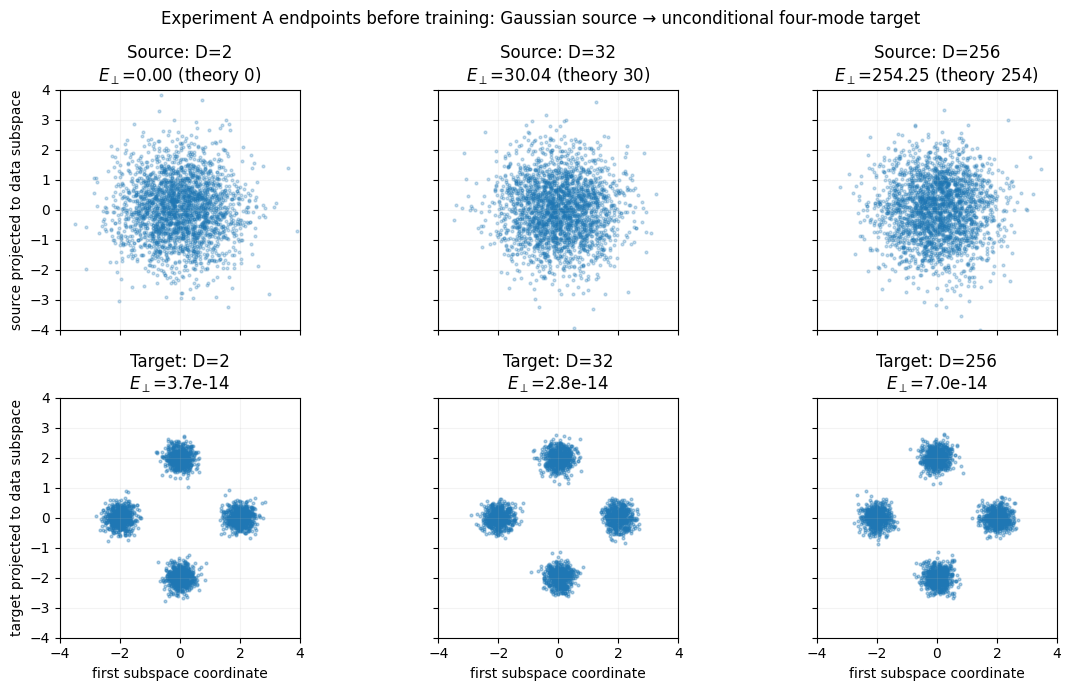

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)
distribution_samples = {}
for column, ambient_dim in enumerate([2, 32, 256]):
    basis = make_basis(ambient_dim, seed=777)
    x0, x1, z1 = sample_pair(2500, basis)
    source_projection = (x0 @ basis).cpu().numpy()
    target_projection = (x1 @ basis).cpu().numpy()
    source_perp = float(split_energy(x0, basis)[1].mean())
    target_perp = float(split_energy(x1, basis)[1].mean())
    distribution_samples[ambient_dim] = {
        "source_projection": source_projection,
        "target_projection": target_projection,
        "source_perpendicular_energy": source_perp,
        "target_perpendicular_energy": target_perp,
    }

    axes[0, column].scatter(source_projection[:, 0], source_projection[:, 1], s=4, alpha=0.25)
    axes[1, column].scatter(target_projection[:, 0], target_projection[:, 1], s=4, alpha=0.35)
    axes[0, column].set_title(f"Source: D={ambient_dim}\n$E_\\perp$={source_perp:.2f} (theory {ambient_dim-2})")
    axes[1, column].set_title(f"Target: D={ambient_dim}\n$E_\\perp$={target_perp:.1e}")
    for row in range(2):
        axes[row, column].set_aspect("equal")
        axes[row, column].grid(alpha=0.15)
        axes[row, column].set_xlim(-4, 4)
        axes[row, column].set_ylim(-4, 4)

axes[0, 0].set_ylabel("source projected to data subspace")
axes[1, 0].set_ylabel("target projected to data subspace")
for ax in axes[1]:
    ax.set_xlabel("first subspace coordinate")
fig.suptitle("Experiment A endpoints before training: Gaussian source → unconditional four-mode target")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "02_experiment_A_source_target.png", dpi=170)
plt.show()

### 4.2 解析速度场基准：先排除积分器问题

这个二维高斯混合路径的边际速度场可以解析计算。对第 $k$ 个分量：

$$
x_t\mid k\sim\mathcal N\!\left(t\mu_k,\left[(1-t)^2+t^2\sigma^2\right]I\right).
$$

先用解析速度场采样，再比较 8、24、50、100 个积分步。如果 24 步已经接近真实目标，神经网络结果呈连续圆环就应归因于训练误差，而不是 ODE 步数不足。

real target: {'nearest_mode_rmse': 0.35549452900886536, 'target_nll': 2.155740737915039}
{'ode_steps': 8, 'nearest_mode_rmse': 0.36470502614974976, 'target_nll': 2.208807945251465}
{'ode_steps': 24, 'nearest_mode_rmse': 0.35787326097488403, 'target_nll': 2.169316291809082}
{'ode_steps': 50, 'nearest_mode_rmse': 0.3566974401473999, 'target_nll': 2.1625940799713135}
{'ode_steps': 100, 'nearest_mode_rmse': 0.35637983679771423, 'target_nll': 2.1607823371887207}


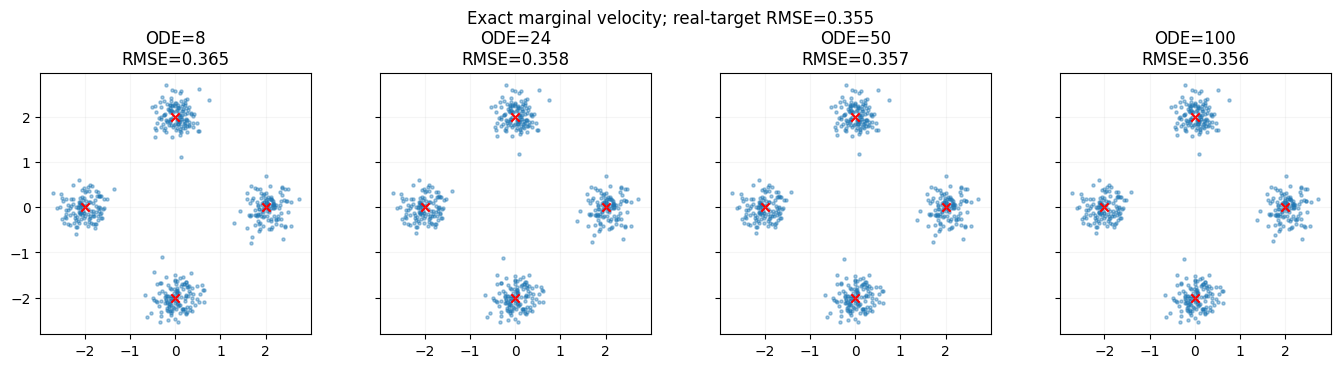

In [7]:
@torch.no_grad()
def exact_gmm_velocity(x, t, sigma=TARGET_STD):
    centers = MODE_CENTERS.to(x.device)
    variance = (1-t).square() + t.square()*sigma**2
    residual = x[:, None, :] - t[:, None, :]*centers[None]
    posterior = torch.softmax(-residual.square().sum(-1)/(2*variance), dim=1)
    coefficient = (t*sigma**2-(1-t))/variance
    component_velocity = centers[None] + coefficient[:, None, :]*residual
    return (posterior[:, :, None]*component_velocity).sum(1)

@torch.no_grad()
def sample_exact_gmm(n, steps, t_end=0.999):
    generator = torch.Generator(device=DEVICE).manual_seed(2026)
    x = torch.randn(n, 2, device=DEVICE, generator=generator)
    dt = t_end/steps
    for i in range(steps):
        left = torch.full((n, 1), i*dt, device=DEVICE)
        middle = left + 0.5*dt
        k1 = exact_gmm_velocity(x, left)
        k2 = exact_gmm_velocity(x+0.5*dt*k1, middle)
        x = x + dt*k2
    return x

def mode_fit_metrics(z):
    dist2 = torch.cdist(z, MODE_CENTERS.to(z.device)).square()
    nearest_rmse = dist2.min(1).values.mean().sqrt()
    component_logp = -dist2/(2*TARGET_STD**2)-math.log(2*math.pi*TARGET_STD**2)
    nll = -(torch.logsumexp(component_logp, 1)-math.log(8)).mean()
    return float(nearest_rmse), float(nll)

exact_rows, exact_samples = [], {}
for steps in [8, 24, 50, 100]:
    samples = sample_exact_gmm(2048, steps)
    rmse, nll = mode_fit_metrics(samples)
    exact_rows.append({"ode_steps": steps, "nearest_mode_rmse": rmse, "target_nll": nll})
    exact_samples[steps] = samples[:512].cpu().numpy()

real_reference = sample_latent(2048)
real_rmse, real_nll = mode_fit_metrics(real_reference)
print("real target:", {"nearest_mode_rmse": real_rmse, "target_nll": real_nll})
for row in exact_rows:
    print(row)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharex=True, sharey=True)
centers = MODE_CENTERS.numpy()
for ax, row in zip(axes, exact_rows):
    z = exact_samples[row["ode_steps"]]
    ax.scatter(z[:, 0], z[:, 1], s=5, alpha=0.4)
    ax.scatter(centers[:, 0], centers[:, 1], c="red", marker="x")
    ax.set_title(f"ODE={row['ode_steps']}\nRMSE={row['nearest_mode_rmse']:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.12)
fig.suptitle(f"Exact marginal velocity; real-target RMSE={real_rmse:.3f}")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_exact_velocity_ode_baseline.png", dpi=170)
plt.show()

In [8]:
experiment_a = []
a_samples = {}
start_time = time.time()
for ambient_dim in [2, 32, 256]:
    for loss_type in ["x", "eps", "v"]:
        for pred_type in ["x", "eps", "v"]:
            seed = stable_seed("A", ambient_dim)
            model, basis, losses = train_toy_model(
                ambient_dim, pred_type, loss_type, hidden=128,
                steps=STEPS["A"], delta=0.01, lr=2e-3, use_ema=False, seed=seed,
            )
            metrics, samples = evaluate_toy(model, basis, pred_type, losses)
            row = {"D": ambient_dim, "loss": loss_type, "prediction": pred_type, **metrics}
            experiment_a.append(row)
            # 保存全部 27 个模型的二维投影样本，用于逐组可视化。
            a_samples[(ambient_dim, loss_type, pred_type)] = samples
            print(f"A D={ambient_dim:3d} loss={loss_type:3s} pred={pred_type:3s} "
                  f"modeRMSE={metrics['nearest_mode_rmse']:.3f} Eperp={metrics['generated_perpendicular_energy']:.3f}")
            release_model(model)
print(f"Experiment A runtime: {time.time()-start_time:.1f}s")

A D=  2 loss=x   pred=x   modeRMSE=0.366 Eperp=0.000


A D=  2 loss=x   pred=eps modeRMSE=1.208 Eperp=0.000


A D=  2 loss=x   pred=v   modeRMSE=0.298 Eperp=0.000


A D=  2 loss=eps pred=x   modeRMSE=0.412 Eperp=0.000


A D=  2 loss=eps pred=eps modeRMSE=0.378 Eperp=0.000


...

A D=256 loss=eps pred=eps modeRMSE=71.516 Eperp=513042.312


A D=256 loss=eps pred=v   modeRMSE=1.332 Eperp=192.716


A D=256 loss=v   pred=x   modeRMSE=0.648 Eperp=0.089


A D=256 loss=v   pred=eps modeRMSE=70.750 Eperp=479721.750


A D=256 loss=v   pred=v   modeRMSE=1.240 Eperp=179.886
Experiment A runtime: 147.6s


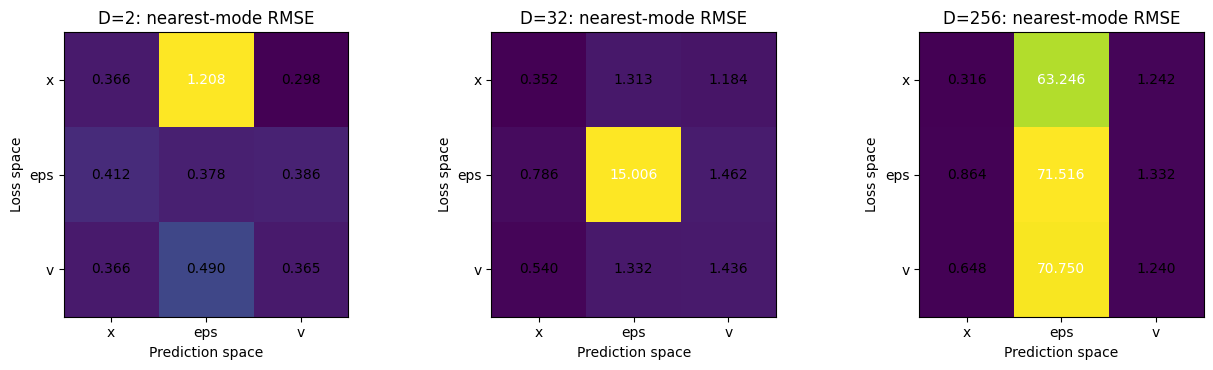

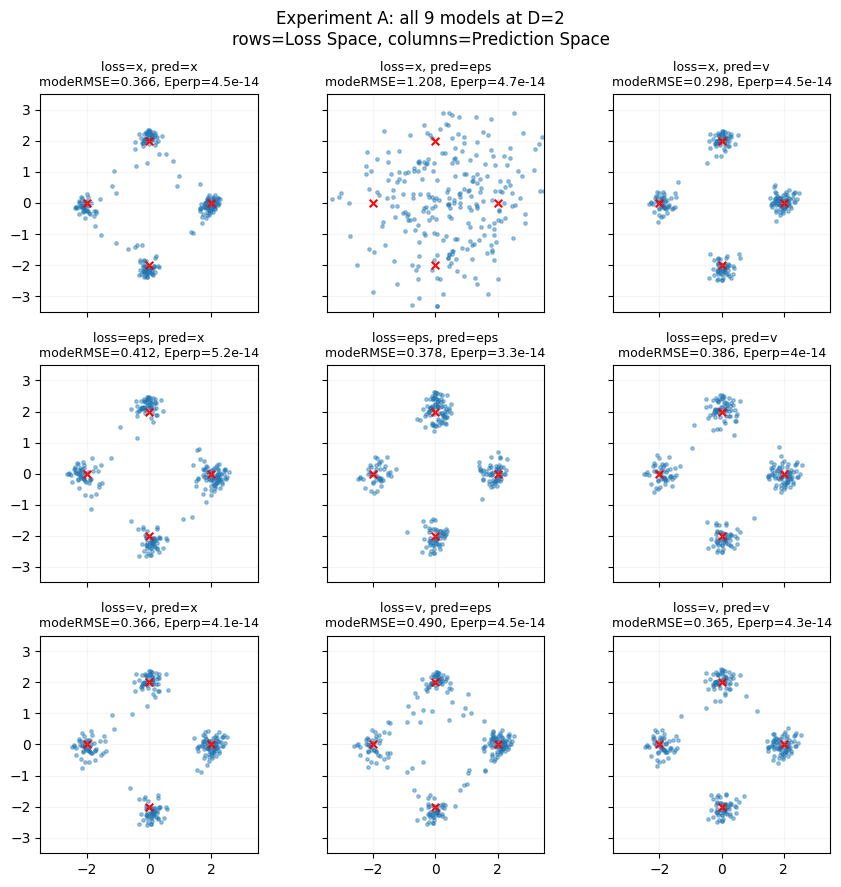

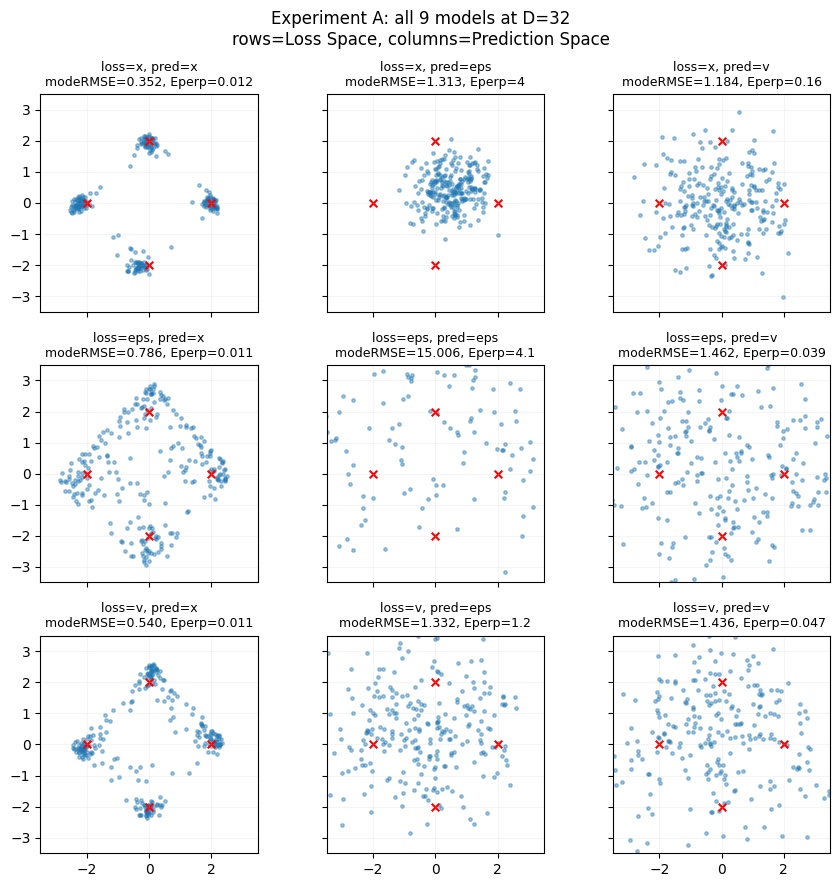

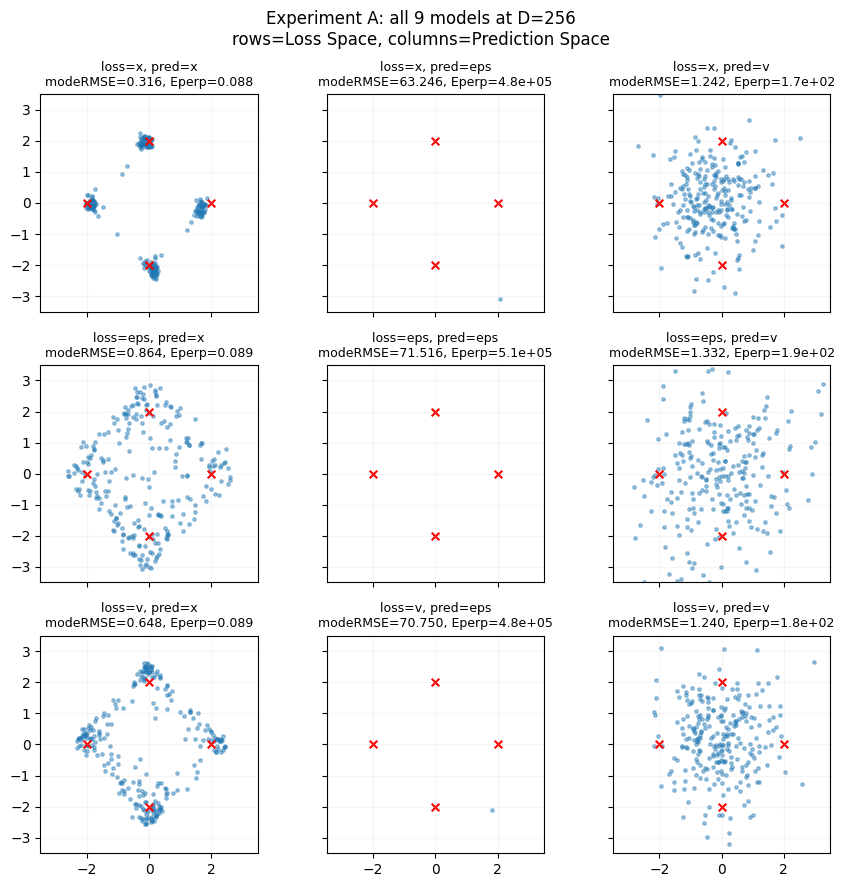

In [9]:
pred_names = ["x", "eps", "v"]
loss_names = ["x", "eps", "v"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, ambient_dim in zip(axes, [2, 32, 256]):
    matrix = np.array([[next(r["nearest_mode_rmse"] for r in experiment_a
                              if r["D"] == ambient_dim and r["loss"] == loss and r["prediction"] == pred)
                        for pred in pred_names] for loss in loss_names])
    image = ax.imshow(matrix, cmap="viridis")
    ax.set_xticks(range(3), pred_names)
    ax.set_yticks(range(3), loss_names)
    ax.set(xlabel="Prediction space", ylabel="Loss space", title=f"D={ambient_dim}: nearest-mode RMSE")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{matrix[i,j]:.3f}", ha="center", va="center", color="white" if matrix[i,j] > matrix.max()/2 else "black")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "03_experiment_A_heatmaps.png", dpi=160)
plt.show()

# 每个环境维度各画一张 3×3 图；三张图合计展示全部 27 个模型。
centers = MODE_CENTERS.numpy()
for ambient_dim in [2, 32, 256]:
    fig, axes = plt.subplots(3, 3, figsize=(9, 9), sharex=True, sharey=True)
    for i, loss in enumerate(loss_names):
        for j, pred in enumerate(pred_names):
            z = a_samples[(ambient_dim, loss, pred)]
            row = next(r for r in experiment_a
                       if r["D"] == ambient_dim and r["loss"] == loss and r["prediction"] == pred)
            axes[i, j].scatter(z[:, 0], z[:, 1], s=6, alpha=0.42)
            axes[i, j].scatter(centers[:, 0], centers[:, 1], c="red", marker="x", s=30)
            axes[i, j].set_title(
                f"loss={loss}, pred={pred}\nmodeRMSE={row['nearest_mode_rmse']:.3f}, Eperp={row['generated_perpendicular_energy']:.2g}",
                fontsize=9,
            )
            axes[i, j].set_aspect("equal")
            axes[i, j].set_xlim(-3.5, 3.5)
            axes[i, j].set_ylim(-3.5, 3.5)
            axes[i, j].grid(alpha=0.12)
    fig.suptitle(f"Experiment A: all 9 models at D={ambient_dim}\nrows=Loss Space, columns=Prediction Space")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"03_experiment_A_samples_D{ambient_dim}.png", dpi=170)
    plt.show()

### 4.3 主实验运行结论

解析速度场基准表明，RK2 Midpoint 使用 24 个区间时最近峰 RMSE 已为 0.358，50 个区间为 0.357；真实目标样本约为 0.355。因此，30 个积分区间足以完成这个四峰任务，求解器离散误差不是此前连续圆环现象的主要来源。

修正训练和目标分布后，第一列 x-prediction 在三个环境维度下都能形成四个峰：

| 环境维度 | x-loss + x-pred | v-loss + x-pred | 生成样本正交补能量 |
|---:|---:|---:|---:|
| $D=2$ | RMSE 0.366 | RMSE 0.366 | 数值零 |
| $D=32$ | RMSE 0.352 | RMSE 0.540 | 约 0.011 |
| $D=256$ | RMSE 0.316 | RMSE 0.648 | 约 0.089 |

相反，直接预测噪声和速度在高维环境中仍会保留大量正交补分量。例如 $D=256$ 时，v-prediction 的生成正交补能量约为 $1.7\times10^2$ 至 $1.9\times10^2$，部分 $\epsilon$-prediction 组合达到约 $4.8\times10^5$。

因此四峰版本同时满足两个目的：低维第一组确实能够训练成功；环境维度提高后，不同 Prediction Space 的差异仍然清楚可见。这里所有模型都是无条件模型，四个峰的编号没有输入网络。

## 5. 实验 B：网络容量瓶颈

固定 $D=256$ 和 v-loss，改变隐藏宽度 $H\in\{32,64,128,256\}$。重点观察正交补速度误差是否随着容量增加而下降。

B H= 32 pred=x   perp=0.040


B H= 32 pred=eps perp=3466.312


B H= 32 pred=v   perp=238.759


B H= 64 pred=x   perp=0.022


B H= 64 pred=eps perp=4065.345


...

B H=128 pred=eps perp=4363.566


B H=128 pred=v   perp=199.689


B H=256 pred=x   perp=0.007


B H=256 pred=eps perp=3563.402


B H=256 pred=v   perp=159.182


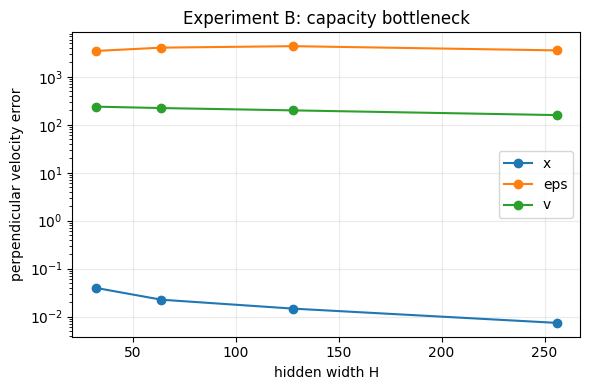

In [10]:
experiment_b = []
for hidden in [32, 64, 128, 256]:
    for pred_type in ["x", "eps", "v"]:
        model, basis, losses = train_toy_model(
            256, pred_type, "v", hidden=hidden, steps=STEPS["B"],
            seed=stable_seed("B", hidden, pred_type),
        )
        metrics, _ = evaluate_toy(model, basis, pred_type, losses)
        experiment_b.append({"hidden": hidden, "prediction": pred_type, **metrics})
        print(f"B H={hidden:3d} pred={pred_type:3s} perp={metrics['perpendicular_velocity_error']:.3f}")
        release_model(model)

fig, ax = plt.subplots(figsize=(6, 4))
for pred in pred_names:
    rows = [r for r in experiment_b if r["prediction"] == pred]
    ax.plot([r["hidden"] for r in rows], [r["perpendicular_velocity_error"] for r in rows], "o-", label=pred)
ax.set(xlabel="hidden width H", ylabel="perpendicular velocity error", title="Experiment B: capacity bottleneck")
ax.set_yscale("log")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "04_experiment_B_capacity.png", dpi=160)
plt.show()

## 6. 实验 C：解析残差参数化

比较直接速度预测、x-prediction 和显式速度残差：

$$
\hat v_{\rm direct}=f_\theta(x_t,t),\quad
\hat v_x=\frac{f_\theta(x_t,t)-x_t}{1-t},\quad
\hat v_{\rm skip}=f_\theta(x_t,t)-\frac{x_t}{1-t}.
$$

V-Skip 与 x-prediction 具有紧密的函数重参数化关系，本实验比较其优化行为，不把结果解释成表达能力定理。

C v     : MMD²=0.0494, perp=197.621


C x     : MMD²=0.0067, perp=0.014


C v_skip: MMD²=0.0337, perp=0.005


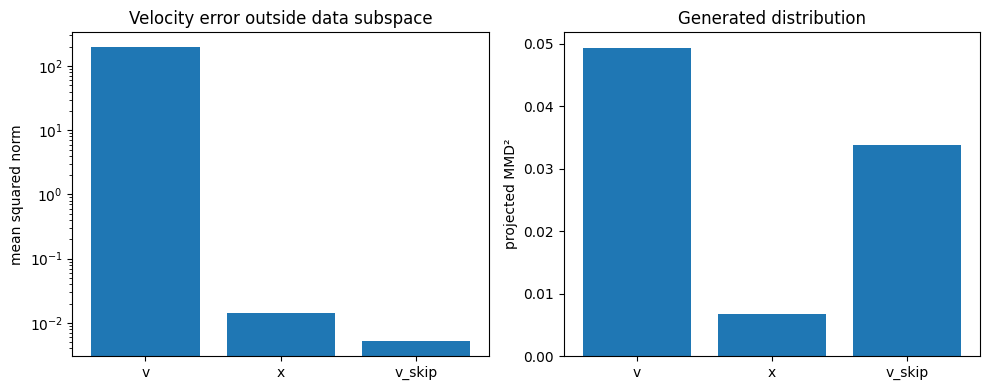

In [11]:
experiment_c = []
for pred_type in ["v", "x", "v_skip"]:
    model, basis, losses = train_toy_model(
        256, pred_type, "v", hidden=128, steps=STEPS["C"],
        seed=stable_seed("C", pred_type),
    )
    metrics, samples = evaluate_toy(model, basis, pred_type, losses)
    experiment_c.append({"parameterization": pred_type, **metrics})
    print(f"C {pred_type:6s}: MMD²={metrics['mmd2']:.4f}, perp={metrics['perpendicular_velocity_error']:.3f}")
    release_model(model)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
labels = [r["parameterization"] for r in experiment_c]
axes[0].bar(labels, [r["perpendicular_velocity_error"] for r in experiment_c])
axes[0].set(title="Velocity error outside data subspace", ylabel="mean squared norm")
axes[0].set_yscale("log")
axes[1].bar(labels, [r["mmd2"] for r in experiment_c])
axes[1].set(title="Generated distribution", ylabel="projected MMD²")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "05_experiment_C_residual.png", dpi=160)
plt.show()

## 7. 实验 E：噪声协方差消融

构造：

$$
x_0=\sigma_\parallel\Pi\epsilon+\sigma_\perp(I-\Pi)\epsilon,
$$

固定 $\sigma_\parallel=1$，令 $\sigma_\perp\in\{0.25,1,2\}$。理论正交补能量是 $\sigma_\perp^2(D-d)$。除原始误差外，还报告除以该目标能量后的相对误差。

E sigma_perp=0.25 pred=x   normalized=0.0005


E sigma_perp=0.25 pred=eps normalized=17.9312


E sigma_perp=0.25 pred=v   normalized=0.9202


E sigma_perp=1.00 pred=x   normalized=0.0001


E sigma_perp=1.00 pred=eps normalized=11.0410


E sigma_perp=1.00 pred=v   normalized=0.7708


E sigma_perp=2.00 pred=x   normalized=0.0000


E sigma_perp=2.00 pred=eps normalized=17.8813


E sigma_perp=2.00 pred=v   normalized=0.7698


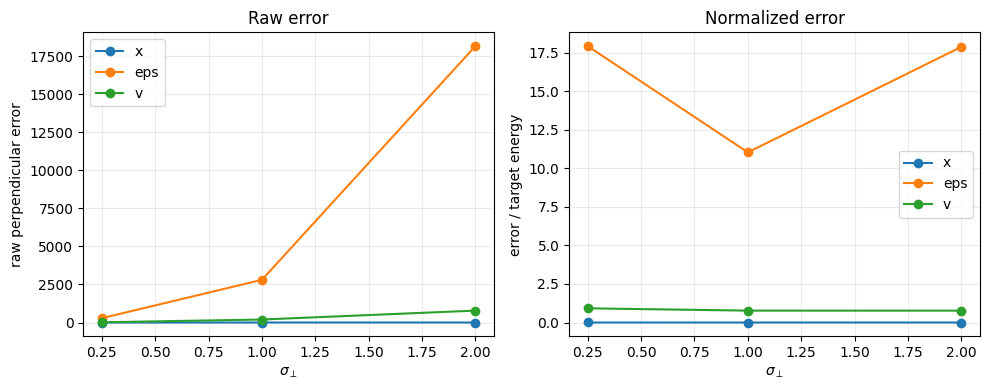

In [12]:
experiment_e = []
for sigma_perp in [0.25, 1.0, 2.0]:
    for pred_type in ["x", "eps", "v"]:
        model, basis, losses = train_toy_model(
            256, pred_type, "v", hidden=128, steps=STEPS["E"],
            sigma_perp=sigma_perp, seed=stable_seed("E", sigma_perp, pred_type),
        )
        metrics, _ = evaluate_toy(model, basis, pred_type, losses, sigma_perp=sigma_perp)
        theory = sigma_perp**2 * (256 - 2)
        metrics["normalized_perpendicular_error"] = metrics["perpendicular_velocity_error"] / theory
        experiment_e.append({"sigma_perp": sigma_perp, "prediction": pred_type, "theory_energy": theory, **metrics})
        print(f"E sigma_perp={sigma_perp:.2f} pred={pred_type:3s} normalized={metrics['normalized_perpendicular_error']:.4f}")
        release_model(model)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for pred in pred_names:
    rows = [r for r in experiment_e if r["prediction"] == pred]
    axes[0].plot([r["sigma_perp"] for r in rows], [r["perpendicular_velocity_error"] for r in rows], "o-", label=pred)
    axes[1].plot([r["sigma_perp"] for r in rows], [r["normalized_perpendicular_error"] for r in rows], "o-", label=pred)
axes[0].set(xlabel=r"$\sigma_\perp$", ylabel="raw perpendicular error", title="Raw error")
axes[1].set(xlabel=r"$\sigma_\perp$", ylabel="error / target energy", title="Normalized error")
for ax in axes: ax.grid(alpha=0.25); ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "06_experiment_E_covariance.png", dpi=160)
plt.show()

## 8. 实验 G：时间区间消融

不同参数化在端点附近有不同的数值条件。这里令 $t\sim U[\delta,1-\delta]$，比较 $\delta\in\{0.01,0.05,0.1\}$，并在十个时间区间上单独统计速度误差 $L_v(t)$。

G delta=0.01 pred=x   velocity=5.012


G delta=0.01 pred=eps velocity=13912.521


G delta=0.01 pred=v   velocity=208.344


G delta=0.05 pred=x   velocity=4.414


G delta=0.05 pred=eps velocity=3565.300


G delta=0.05 pred=v   velocity=206.259


G delta=0.10 pred=x   velocity=4.418


G delta=0.10 pred=eps velocity=2254.971


G delta=0.10 pred=v   velocity=203.270


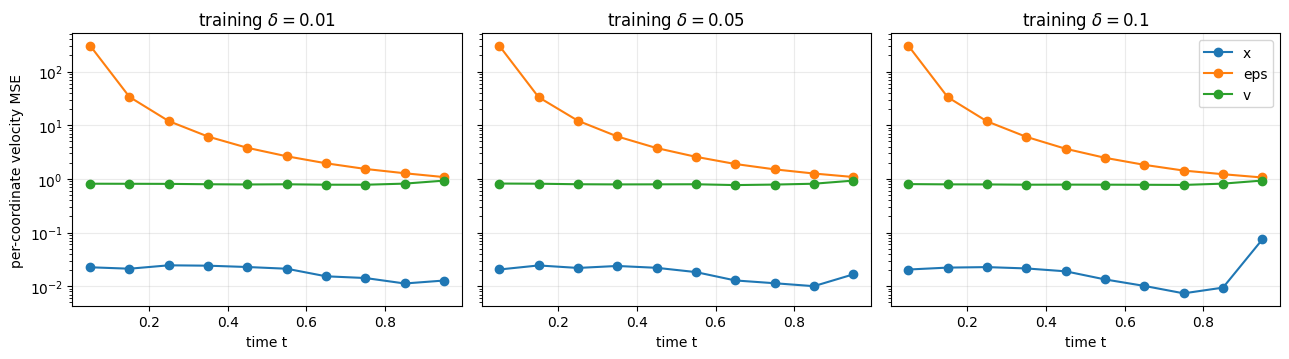

In [13]:
@torch.no_grad()
def binned_velocity_error(model, basis, pred_type, bins=10):
    values = []
    for i in range(bins):
        t_value = (i + 0.5) / bins
        x0, x1, _ = sample_pair(256, basis)
        t = torch.full((256, 1), t_value, device=DEVICE)
        xt = (1-t)*x0 + t*x1
        pred_v = convert_prediction(model(xt, t), xt, t, pred_type)[2]
        values.append(float((pred_v-(x1-x0)).square().mean()))
    return values

experiment_g = []
g_curves = {}
for delta in [0.01, 0.05, 0.10]:
    for pred_type in ["x", "eps", "v"]:
        model, basis, losses = train_toy_model(
            256, pred_type, "v", hidden=128, steps=STEPS["G"], delta=delta,
            seed=stable_seed("G", delta, pred_type),
        )
        metrics, _ = evaluate_toy(model, basis, pred_type, losses, delta=delta)
        curve = binned_velocity_error(model, basis, pred_type)
        experiment_g.append({"delta": delta, "prediction": pred_type, **metrics})
        g_curves[(delta, pred_type)] = curve
        print(f"G delta={delta:.2f} pred={pred_type:3s} velocity={metrics['velocity_mse']:.3f}")
        release_model(model)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.7), sharey=True)
t_centers = (np.arange(10) + 0.5) / 10
for ax, delta in zip(axes, [0.01, 0.05, 0.10]):
    for pred in pred_names:
        ax.plot(t_centers, g_curves[(delta, pred)], "o-", label=pred)
    ax.set(xlabel="time t", title=fr"training $\delta={delta}$")
    ax.set_yscale("log")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("per-coordinate velocity MSE")
axes[-1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "07_experiment_G_time.png", dpi=160)
plt.show()

## 9. 实验 F：简化 JiT 生成程序化数字“2”

前面的数据严格位于二维线性子空间。这里改用 $32\times32$ 程序化灰度图像，使目标分布具有空间结构和非线性变化。

模型是小型 JiT 风格 Transformer：图像被拆成 $4\times4$ patch，共 64 个 token；时间嵌入加入每个 token；Transformer 输出再还原为像素图像。该模型用于机制验证，并非论文完整 JiT 架构的逐层复现。

torch.Size([4096, 1, 32, 32]) -1.0 1.0


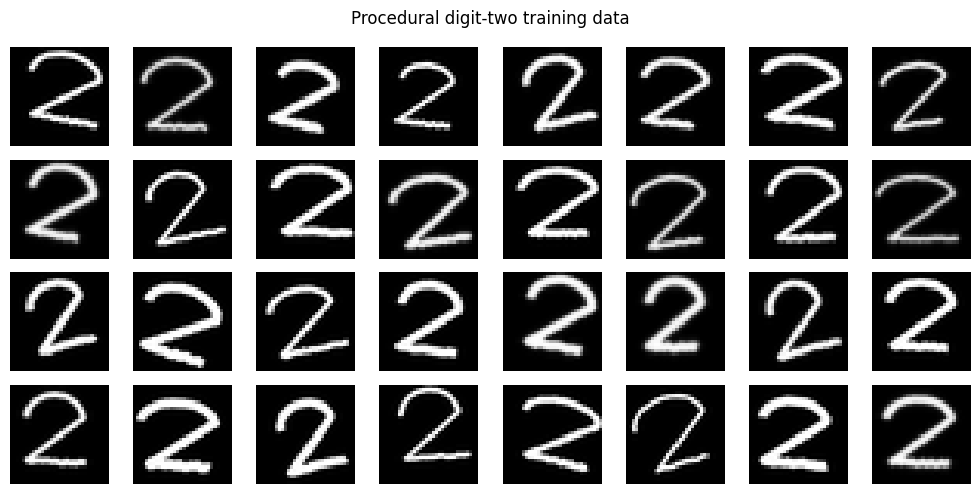

In [14]:
def make_digit_two(index, image_size=32, seed=42):
    rng = random.Random(seed + index)
    scale, size = 4, image_size * 4
    image = Image.new("L", (size, size), color=0)
    draw = ImageDraw.Draw(image)
    shift_x, shift_y = rng.uniform(-2, 2), rng.uniform(-2, 2)
    width, angle = rng.uniform(1.7, 3.2), rng.uniform(-18, 18)
    top_width, top_height = rng.uniform(8, 12), rng.uniform(5, 8)
    bottom_width = rng.uniform(9, 13)
    points = []
    for i in range(35):
        u = i / 34
        theta = math.pi * (1-u)
        points.append((16 + top_width*math.cos(theta), 11 - top_height*math.sin(theta)))
    start_x, start_y = points[-1]
    for i in range(1, 25):
        u = i / 24
        points.append((start_x*(1-u)+7.5*u, start_y*(1-u)+25*u))
    for i in range(1, 25):
        u = i / 24
        points.append((7.5 + bottom_width*1.7*u, 25 + rng.uniform(-0.4, 0.4)))
    points = [(int((x+shift_x)*scale), int((y+shift_y)*scale)) for x, y in points]
    draw.line(points, fill=255, width=max(1, int(width*scale)), joint="curve")
    image = image.rotate(angle, resample=Image.Resampling.BICUBIC, fillcolor=0)
    image = image.resize((image_size, image_size), Image.Resampling.LANCZOS)
    if rng.random() < 0.5:
        image = image.filter(ImageFilter.GaussianBlur(radius=rng.uniform(0.1, 0.5)))
    array = np.asarray(image, dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(array).unsqueeze(0)

# 预生成数据，训练时只做 GPU 索引，保证三种参数化看到同一数据分布。
train_images = torch.stack([make_digit_two(i, seed=42) for i in range(4096)])
val_images = torch.stack([make_digit_two(i, seed=100000) for i in range(512)])
print(train_images.shape, train_images.min().item(), train_images.max().item())

fig, axes = plt.subplots(4, 8, figsize=(10, 5))
for image, ax in zip(train_images[:32], axes.flat):
    ax.imshow(image[0], cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
fig.suptitle("Procedural digit-two training data")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "08_digit_two_dataset.png", dpi=160)
plt.show()

In [15]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim*4), nn.SiLU(), nn.Linear(dim*4, dim))

    def forward(self, t):
        half = self.dim // 2
        frequencies = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / max(half-1, 1))
        angles = 2*math.pi*t[:, None] * frequencies[None]
        return self.mlp(torch.cat([angles.sin(), angles.cos()], dim=-1))

class TinyJiT(nn.Module):
    def __init__(self, image_size=32, patch_size=4, hidden=64, depth=2, heads=4):
        super().__init__()
        self.image_size, self.patch_size = image_size, patch_size
        self.grid = image_size // patch_size
        self.patch_embed = nn.Conv2d(1, hidden, patch_size, patch_size)
        self.pos_embed = nn.Parameter(torch.randn(1, self.grid**2, hidden) * 0.02)
        self.time_embed = TimeEmbedding(hidden)
        layer = nn.TransformerEncoderLayer(hidden, heads, hidden*4, dropout=0.0,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(hidden)
        self.head = nn.Linear(hidden, patch_size**2)

    def forward(self, x, t):
        batch = len(x)
        h = self.patch_embed(x).flatten(2).transpose(1, 2)
        h = h + self.pos_embed + self.time_embed(t)[:, None]
        h = self.head(self.norm(self.transformer(h)))
        p, g = self.patch_size, self.grid
        return h.reshape(batch, g, g, p, p).permute(0, 1, 3, 2, 4).reshape(batch, 1, self.image_size, self.image_size)

def image_velocity(model, xt, t, pred_type):
    raw = model(xt, t)
    t4 = t[:, None, None, None]
    if pred_type == "x":
        return (raw - xt) / (1-t4).clamp_min(1e-3)
    if pred_type == "eps":
        return (xt - raw) / t4.clamp_min(1e-3)
    return raw

def train_jit(pred_type, steps=600, batch_size=48, delta=0.05):
    set_seed(stable_seed("F", pred_type))
    model = TinyJiT().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.01)
    losses = []
    model.train()
    for _ in range(steps):
        ids = torch.randint(len(train_images), (batch_size,))
        x1 = train_images[ids].to(DEVICE)
        x0 = torch.randn_like(x1)
        t = delta + (1-2*delta)*torch.rand(batch_size, device=DEVICE)
        t4 = t[:, None, None, None]
        xt = (1-t4)*x0 + t4*x1
        loss = F.mse_loss(image_velocity(model, xt, t, pred_type), x1-x0)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        losses.append(float(loss.detach()))
    return model.eval(), losses

@torch.no_grad()
def sample_jit(model, pred_type, n=128, steps=40, chunk=64):
    outputs = []
    for start in range(0, n, chunk):
        batch = min(chunk, n-start)
        x = torch.randn(batch, 1, 32, 32, device=DEVICE)
        dt = 1/steps
        for i in range(steps):
            t = torch.full((batch,), (i+0.5)*dt, device=DEVICE)
            x = x + dt*image_velocity(model, x, t, pred_type)
        outputs.append(x.cpu())
    return torch.cat(outputs)

def image_mmd(real, fake, scale=8):
    real = F.adaptive_avg_pool2d(real, (scale, scale)).flatten(1)
    fake = F.adaptive_avg_pool2d(fake, (scale, scale)).flatten(1)
    dxx = torch.cdist(real, real).square()
    bandwidth = dxx[dxx > 0].median().clamp_min(1e-6)
    kxx = torch.exp(-dxx/bandwidth)
    kyy = torch.exp(-torch.cdist(fake, fake).square()/bandwidth)
    kxy = torch.exp(-torch.cdist(real, fake).square()/bandwidth)
    n, m = len(real), len(fake)
    return float(((kxx.sum()-kxx.diag().sum())/(n*(n-1)) +
                  (kyy.sum()-kyy.diag().sum())/(m*(m-1)) - 2*kxy.mean()))

def diversity(images):
    flat = F.adaptive_avg_pool2d(images, (8, 8)).flatten(1)
    return float(torch.pdist(flat).square().mean())

In [16]:
jit_models, jit_losses, jit_samples, experiment_f = {}, {}, {}, []
for pred_type in ["x", "eps", "v"]:
    start = time.time()
    model, losses = train_jit(pred_type, steps=STEPS["F"])
    samples = sample_jit(model, pred_type, n=128, steps=40)
    real = val_images[:128]
    metrics = {
        "prediction": pred_type,
        "final_train_loss": float(np.mean(losses[-50:])),
        "mmd8": image_mmd(real, samples),
        "generated_diversity": diversity(samples),
        "real_diversity": diversity(real),
    }
    jit_models[pred_type], jit_losses[pred_type], jit_samples[pred_type] = model, losses, samples
    experiment_f.append(metrics)
    print(f"F pred={pred_type:3s} loss={metrics['final_train_loss']:.4f} "
          f"MMD8={metrics['mmd8']:.4f} diversity={metrics['generated_diversity']:.3f} "
          f"runtime={time.time()-start:.1f}s")

F pred=x   loss=0.4251 MMD8=0.0811 diversity=15.175 runtime=6.1s


F pred=eps loss=0.5339 MMD8=0.2341 diversity=85.903 runtime=5.4s


F pred=v   loss=0.3791 MMD8=0.0314 diversity=10.802 runtime=5.3s


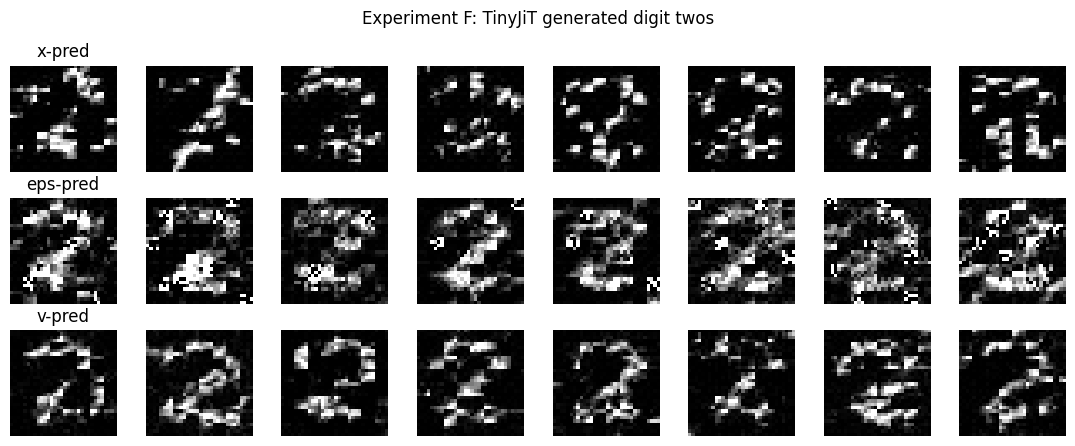

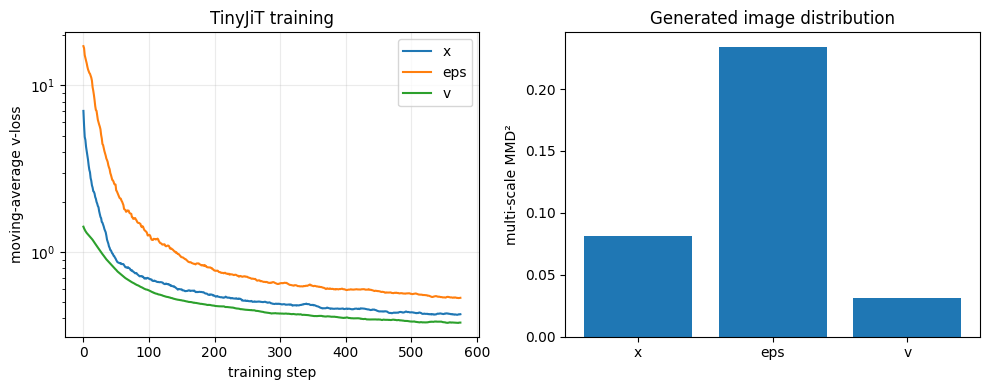

In [17]:
fig, axes = plt.subplots(3, 8, figsize=(11, 4.5))
for row, pred in enumerate(pred_names):
    images = jit_samples[pred].clamp(-1, 1)
    for col in range(8):
        axes[row, col].imshow(images[col, 0], cmap="gray", vmin=-1, vmax=1)
        axes[row, col].axis("off")
    axes[row, 0].set_title(f"{pred}-pred")
fig.suptitle("Experiment F: TinyJiT generated digit twos")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "09_experiment_F_generated_digits.png", dpi=180)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for pred in pred_names:
    curve = np.convolve(jit_losses[pred], np.ones(25)/25, mode="valid")
    axes[0].plot(curve, label=pred)
axes[0].set(xlabel="training step", ylabel="moving-average v-loss", title="TinyJiT training")
axes[0].set_yscale("log")
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].bar(pred_names, [next(r["mmd8"] for r in experiment_f if r["prediction"] == p) for p in pred_names])
axes[1].set(ylabel="multi-scale MMD²", title="Generated image distribution")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "10_experiment_F_metrics.png", dpi=160)
plt.show()

## 10. 保存结果并生成实验结论

本实验的短训练配置主要用于验证代码、观察趋势和比较机制。MMD 可能出现轻微负值，因为这里使用的是无偏有限样本估计；这不代表真实的 MMD 平方小于零。

结论应同时参考训练误差、正交补误差、分布指标和样本图，不能仅依赖单个指标。尤其是：

- $D-d$ 关系是严格的期望恒等式。
- Prediction Space 的性能差异是有限网络和具体优化设置下的经验结果。
- V-Skip 是参数化消融，不能单独证明表达能力差异。
- 程序化数字实验是小型机制验证，不能替代论文中的 ImageNet 实验。

In [18]:
all_metrics = {
    "configuration": {
        "quick_run": QUICK_RUN,
        "device": str(DEVICE),
        "steps": STEPS,
        "ode_steps": ODE_STEPS,
        "seed": SEED,
    },
    "D_projection_energy": energy_rows,
    "exact_velocity_ode_baseline": exact_rows,
    "D_orientation_values": orientation_values,
    "A_prediction_loss_dimension": experiment_a,
    "B_capacity": experiment_b,
    "C_residual": experiment_c,
    "E_covariance": experiment_e,
    "G_time_interval": experiment_g,
    "F_tiny_jit": experiment_f,
}
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(all_metrics, file, ensure_ascii=False, indent=2)

best_a = min(experiment_a, key=lambda row: row["nearest_mode_rmse"])
best_f = min(experiment_f, key=lambda row: row["mmd8"])
print("Results saved to:", OUTPUT_DIR.resolve())
print("A best nearest-mode RMSE:", best_a)
print("F best multi-scale MMD²:", best_f)
print("Projection max absolute theory error:", max(abs(r["noise_perp"]-r["theory_perp"]) for r in energy_rows))

Results saved to: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/let_dgm_outputs
A best nearest-mode RMSE: {'D': 2, 'loss': 'x', 'prediction': 'v', 'final_train_loss': 0.8063690662384033, 'velocity_mse': 3.971021890640259, 'parallel_velocity_error': 3.9710211753845215, 'perpendicular_velocity_error': 4.746192927063998e-14, 'generated_perpendicular_energy': 4.487729632352e-14, 'mmd2': 0.017227351665496826, 'mode_coverage': 4, 'nearest_mode_rmse': 0.2983683943748474, 'target_nll': 1.1637723445892334}
F best multi-scale MMD²: {'prediction': 'v', 'final_train_loss': 0.379051473736763, 'mmd8': 0.031448423862457275, 'generated_diversity': 10.801782608032227, 'real_diversity': 11.341460227966309}
Projection max absolute theory error: 0.029331207275390625


## 11. 如何解读运行结果

运行输出中的结论分为两类：

1. **数学验证**：投影能量应接近 $d$ 和 $D-d$，随机旋转子空间不改变结果。这一部分直接检验理论公式。
2. **训练实验**：比较不同参数化的误差和生成质量。这些结果会受步数、宽度、随机种子和求解器影响，应被解释为当前设置下的实证结果。

若要形成正式报告，建议把 `QUICK_RUN=False`，对关键配置运行至少三个随机种子，并报告均值和标准差。当前 notebook 已把所有指标与图片保存在 `let_dgm_outputs/`，便于后续复现实验和比较。